In [2]:
import os

print(os.listdir('/content'))

['.config', 'Online Retail.xlsx', 'sample_data']


In [3]:

file_path = '/content/Online Retail.xlsx'

with open(file_path, 'rb') as f:
    print(f.read(20))


b'PK\x03\x04\x14\x00\x06\x00\x08\x00\x00\x00!\x00b\xee\x9dh^\x01'


In [4]:

!pip install -q openpyxl

import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx', engine='openpyxl')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:

# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice 

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove rows with missing CustomerID
df_clean = df_clean.dropna(subset=['CustomerID'])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove cancelled invoices
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# Remove invalid quantities and prices
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
]

# Convert CustomerID to integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Create TotalAmount column
df_clean['TotalAmount'] = (
    df_clean['Quantity'] * df_clean['UnitPrice']
)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows After Cleaning:")
print(df_clean.duplicated().sum())

df_clean.head()


Original Dataset Shape: (541909, 8)
Cleaned Dataset Shape: (392692, 9)

Missing Values After Cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate Rows After Cleaning:
0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [7]:

# Set the reference date
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

# Rename columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalAmount': 'Monetary'
}, inplace=True)

# Display RFM data
print("RFM Dataset Shape:", rfm.shape)
display(rfm.head(10))

# Descriptive statistics
display(rfm[['Recency', 'Frequency', 'Monetary']].describe())


RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04
12353,204,1,89.00
12354,232,1,1079.40
12355,214,1,459.40


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [8]:

from sklearn.preprocessing import StandardScaler

# Select RFM features
rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Apply log transformation to reduce skewness
rfm_log = np.log1p(rfm_features)

# Standardise the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert into DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

print("Standardisation completed!")
display(rfm_scaled_df.head())


Standardisation completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


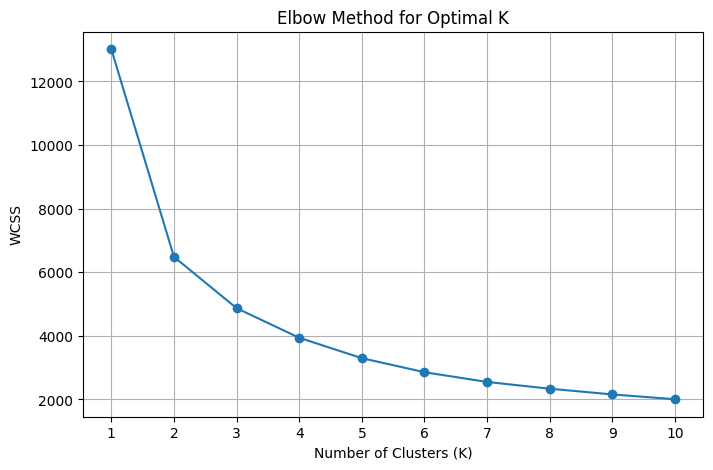

In [9]:

from sklearn.cluster import KMeans

# Calculate WCSS for different cluster numbers
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled_df)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [10]:

# Apply K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled_df)

print("K-Means clustering completed!")

print("\nCustomer count in each cluster:")
print(rfm['Cluster'].value_counts().sort_index())

display(rfm.head(10))


K-Means clustering completed!

Customer count in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,3
12349,19,1,1757.55,2
12350,310,1,334.40,1
12352,36,8,2506.04,3
12353,204,1,89.00,1
12354,232,1,1079.40,1
12355,214,1,459.40,1


In [12]:

# Calculate average RFM values for each cluster
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

# Calculate number of customers in each cluster
cluster_profile['CustomerCount'] = rfm.groupby('Cluster').size()

print("Customer Segment Profiles:")
display(cluster_profile)


Customer Segment Profiles:


,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.32,837
3,71.64,4.08,1801.78,1166


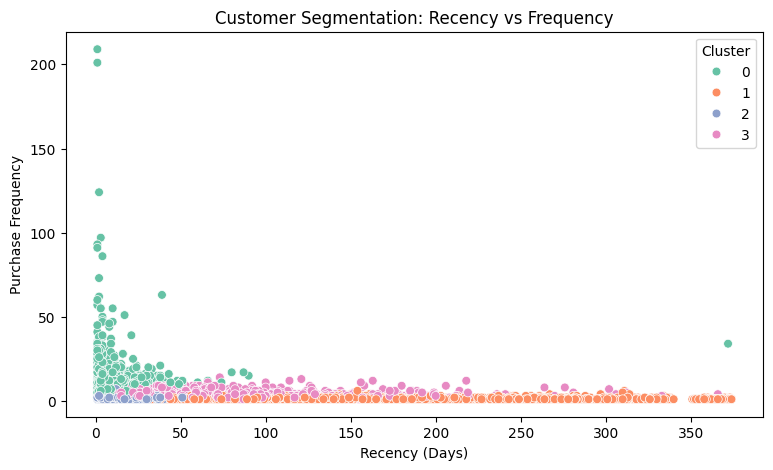

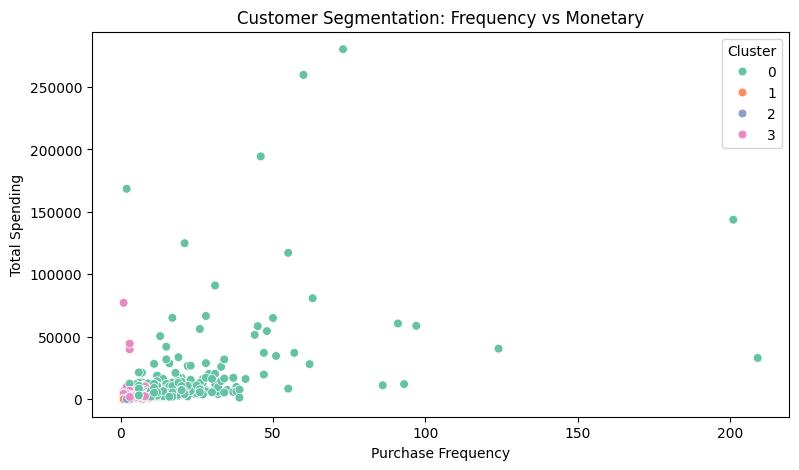

In [13]:

# Scatter plot 1: Recency vs Frequency
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='Set2',
    s=40
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')
plt.legend(title='Cluster')
plt.show()


# Scatter plot 2: Frequency vs Monetary
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    s=40
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')
plt.legend(title='Cluster')
plt.show()


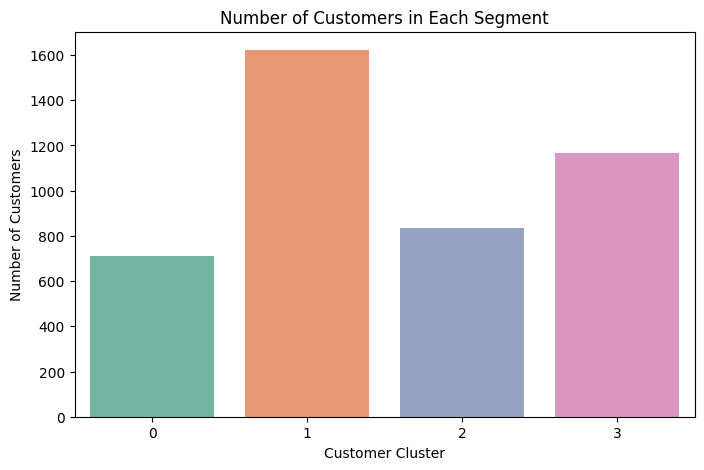

In [14]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x='Cluster',
    hue='Cluster',
    palette='Set2',
    legend=False
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()


## Customer Segmentation Insights and Marketing Recommendations

Based on the K-Means clustering results, customers have been divided into four segments using Recency, Frequency and Monetary (RFM) analysis.

### Cluster 0 – High-Value Customers
These customers show relatively high purchase frequency and spending.

**Marketing Recommendations:**
- Provide loyalty rewards and exclusive discounts.
- Offer VIP membership benefits.
- Encourage repeat purchases through personalised offers.

### Cluster 1 – Low-Engagement Customers
This is the largest customer segment, with relatively low purchase frequency.

**Marketing Recommendations:**
- Send promotional emails and discount coupons.
- Recommend popular products.
- Use personalised campaigns to encourage repeat purchases.

### Cluster 2 – Occasional Customers
These customers show relatively low purchasing activity and spending.

**Marketing Recommendations:**
- Offer bundle deals and seasonal promotions.
- Send product recommendations.
- Encourage customers to make their next purchase.

### Cluster 3 – Moderate-Engagement Customers
These customers demonstrate moderate purchasing behaviour.

**Marketing Recommendations:**
- Introduce loyalty points.
- Provide targeted product recommendations.
- Encourage customers to increase purchase frequency.

### Overall Business Insight
Customer segmentation helps businesses understand different purchasing behaviours and develop targeted marketing strategies. By focusing on customer needs, businesses can improve customer retention, increase sales and build long-term relationships.

In [15]:

# Calculate overall purchase metrics
total_revenue = df_clean['TotalAmount'].sum()
total_invoices = df_clean['InvoiceNo'].nunique()
total_customers = df_clean['CustomerID'].nunique()

average_purchase_value = total_revenue / total_invoices
average_purchase_frequency = rfm['Frequency'].mean()
average_customer_lifetime_value = rfm['Monetary'].mean()

print("CUSTOMER PURCHASE ANALYSIS")
print("--------------------------------")
print("Total Revenue:", round(total_revenue, 2))
print("Total Invoices:", total_invoices)
print("Total Customers:", total_customers)
print("Average Purchase Value:", round(average_purchase_value, 2))
print("Average Purchase Frequency:", round(average_purchase_frequency, 2))
print("Average Customer Lifetime Value:", round(average_customer_lifetime_value, 2))


CUSTOMER PURCHASE ANALYSIS
--------------------------------
Total Revenue: 8887208.89
Total Invoices: 18532
Total Customers: 4338
Average Purchase Value: 479.56
Average Purchase Frequency: 4.27
Average Customer Lifetime Value: 2048.69


## Customer Purchase Analysis – Observations

1. The dataset contains 4,338 unique customers and 18,532 invoices.
2. Total recorded revenue is ₹8,887,208.89.
3. The average purchase value per invoice is ₹479.56.
4. Customers make an average of 4.27 purchases.
5. Average recorded customer spending is ₹2,048.69.

### Conclusion
The analysis demonstrates that customers have different purchasing patterns. RFM analysis and K-Means clustering help identify valuable, frequent and less-engaged customers. These insights can help businesses improve customer retention and develop targeted marketing campaigns.

In [16]:

# Display detailed customer segment profiles
profile = rfm.groupby('Cluster').agg(
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean'),
    Total_Customers=('Cluster', 'size')
).round(2)

print("DETAILED CUSTOMER SEGMENT ANALYSIS")
display(profile)

# Display cluster percentages
profile['Customer_Percentage'] = (
    profile['Total_Customers'] / len(rfm) * 100
).round(2)

display(profile)


DETAILED CUSTOMER SEGMENT ANALYSIS


,Average_Recency,Average_Frequency,Average_Monetary,Total_Customers
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.32,837
3,71.64,4.08,1801.78,1166


,Average_Recency,Average_Frequency,Average_Monetary,Total_Customers,Customer_Percentage
Cluster,,,,,
0,12.17,13.75,8088.02,713,16.44
1,181.51,1.32,341.00,1622,37.39
2,17.70,2.19,557.32,837,19.29
3,71.64,4.08,1801.78,1166,26.88


## Final Customer Segment Insights and Marketing Strategies

### 1. Cluster 0 – Champions
- Customers: 713
- Average spending: ₹8,088.02
- Recommendation: Provide VIP membership, exclusive rewards, referral benefits and personalised offers to retain these valuable customers.

### 2. Cluster 1 – At-Risk Customers
- Customers: 1,622
- Average spending: ₹341.00
- Recommendation: Send re-engagement emails, special comeback discounts and personalised product recommendations to encourage repeat purchases.

### 3. Cluster 2 – Recent Customers
- Customers: 837
- Average spending: ₹557.32
- Recommendation: Offer first-repeat-purchase incentives, product bundles and loyalty points to encourage more frequent purchases.

### 4. Cluster 3 – Regular Customers
- Customers: 1,166
- Average spending: ₹1,801.78
- Recommendation: Introduce loyalty programmes, cross-selling campaigns and personalised promotions to increase customer value.

### Overall Conclusion
K-Means clustering successfully divided 4,338 customers into four meaningful segments using RFM analysis. The results help identify high-value customers, customers at risk of leaving, recent purchasers and regular customers. Businesses can use these insights to improve customer retention, increase revenue and develop targeted marketing strategies.

In [17]:

# Export customer segmentation results
rfm_final = rfm.reset_index()

rfm_final.to_csv(
    'Customer_Segmentation_Results.csv',
    index=False
)

# Export cluster profile summary
profile.to_csv(
    'Customer_Segment_Summary.csv'
)

print("Files saved successfully!")
print("1. Customer_Segmentation_Results.csv")
print("2. Customer_Segment_Summary.csv")


Files saved successfully!
1. Customer_Segmentation_Results.csv
2. Customer_Segment_Summary.csv


In [18]:

from google.colab import files

files.download('Customer_Segmentation_Results.csv')
files.download('Customer_Segment_Summary.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>